# AWS ML Task - Week 01: Market Arrivals Data Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EyobTesfaye8/AWS_tasks/blob/main/week-01/AWS_First_week_task.ipynb)

---

### Project Overview
This notebook presents the data ingestion, cleaning, statistical analysis, and visualization pipeline for agricultural commodity market arrivals.

#### Key Objectives:
1. **Raw Dataset Ingestion**: Load raw market data from local repository with automated remote fallback.
2. **Named Data Cleaning Functions**:
   - Missing value and duplicate handling
   - Text & case normalization (whitespace trimming, uppercase standardization)
   - Data type conversions (datetime parsing and numeric validation)
   - Outlier detection and Winsorization using the Interquartile Range (IQR) method
3. **NumPy Statistical Analysis**:
   - `np.mean()`, `np.median()`, `np.std()`, `np.percentile()`, `np.where()`, `np.min()`, and `np.max()`.
4. **Time-Series Visualization**: Plotting trends across minimum, maximum, and modal market prices.


## 1. Import Essential Libraries

We utilize:
- **requests / os**: Resource management and URL fallbacks
- **pandas**: Tabular data manipulation and type conversion
- **numpy**: High-performance vectorized numerical and statistical operations
- **matplotlib**: Statistical data visualization


In [1]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
print("Libraries successfully imported!")


Libraries successfully imported!


## 2. Load Raw Dataset

Loads the `marketing.csv` file directly from the repository. If not found locally, it retrieves it from the upstream repository URL.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/selva86/datasets/master/MarketArrivals.csv"
DATA_CANDIDATE_PATHS = ["marketing.csv", "week-01/marketing.csv"]

def load_raw_data(candidates=DATA_CANDIDATE_PATHS, fallback_url=DATA_URL) -> pd.DataFrame:
    """
    Loads dataset from local repository candidate paths, or fetches from URL fallback.
    """
    for path in candidates:
        if os.path.exists(path):
            print(f"[INFO] Loaded raw dataset from local repository: '{path}'")
            return pd.read_csv(path)
            
    print(f"[INFO] Local file not found. Fetching from remote URL: {fallback_url}")
    df = pd.read_csv(fallback_url)
    df.to_csv("marketing.csv", index=False)
    print("[INFO] Downloaded and saved dataset to 'marketing.csv'")
    return df

df_raw = load_raw_data()
print(f"Dataset Shape: {df_raw.shape}")
df_raw.head()


[INFO] Loaded raw dataset from local repository: 'marketing.csv'
Dataset Shape: (10227, 10)


,market,month,year,quantity,priceMin,priceMax,priceMod,state,city,date
0,ABOHAR(PB),January,2005,2350,404,493,446,PB,ABOHAR,January-2005
1,ABOHAR(PB),January,2006,900,487,638,563,PB,ABOHAR,January-2006
2,ABOHAR(PB),January,2010,790,1283,1592,1460,PB,ABOHAR,January-2010
3,ABOHAR(PB),January,2011,245,3067,3750,3433,PB,ABOHAR,January-2011
4,ABOHAR(PB),January,2012,1035,523,686,605,PB,ABOHAR,January-2012


## 3. Data Cleaning Pipeline (Named Functions)

We define modular, reusable named functions (`def`) to handle all key data quality dimensions:
1. `clean_missing_and_duplicates`: Detects and resolves missing data and removes duplicate records.
2. `clean_text_fields`: Trims whitespace and normalizes text casing.
3. `convert_column_types`: Parses dates and validates numeric data types.
4. `detect_and_handle_outliers`: Detects outliers using IQR and caps values at threshold boundaries.


In [3]:
def clean_missing_and_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """
    Inspects and handles missing values and duplicate records.
    """
    df_clean = df.copy()
    
    missing_count = df_clean.isna().sum().sum()
    print(f"Missing values found: {missing_count}")
    if missing_count > 0:
        df_clean = df_clean.dropna(subset=['date', 'priceMod', 'quantity'])
        
    dup_count = df_clean.duplicated().sum()
    print(f"Duplicate rows found: {dup_count}")
    if dup_count > 0:
        df_clean = df_clean.drop_duplicates().reset_index(drop=True)
        print(f"Removed {dup_count} duplicate rows.")
        
    return df_clean


def clean_text_fields(df: pd.DataFrame, text_columns: list = None) -> pd.DataFrame:
    """
    Normalizes text fields: trims whitespace and standardizes casing.
    """
    df_clean = df.copy()
    if text_columns is None:
        text_columns = ['market', 'state', 'city']
        
    for col in text_columns:
        if col in df_clean.columns and (
            df_clean[col].dtype == 'object' or pd.api.types.is_string_dtype(df_clean[col])
        ):
            df_clean[col] = df_clean[col].astype(str).str.strip().str.upper()
            print(f"Normalized text & casing for '{col}'")
            
    return df_clean


def convert_column_types(df: pd.DataFrame) -> pd.DataFrame:
    """
    Converts 'date' to datetime64 and ensures numeric columns are properly typed.
    """
    df_clean = df.copy()
    
    if 'date' in df_clean.columns:
        df_clean['date'] = pd.to_datetime(df_clean['date'], format='mixed', dayfirst=False, errors='coerce')
        print("Converted 'date' to datetime64[ns]")
        
    for col in ['month', 'year']:
        if col in df_clean.columns:
            df_clean = df_clean.drop(columns=[col])
            print(f"Dropped redundant column: '{col}'")
            
    for col in ['quantity', 'priceMin', 'priceMax', 'priceMod']:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
            print(f"Validated numeric type for '{col}'")
            
    return df_clean


def detect_and_handle_outliers(df: pd.DataFrame, column: str = 'priceMod', factor: float = 1.5) -> pd.DataFrame:
    """
    Detects outliers using IQR (Interquartile Range) and caps them (Winsorization).
    """
    df_clean = df.copy()
    values = df_clean[column].dropna().to_numpy()
    
    q25, q75 = np.percentile(values, [25, 75])
    iqr = q75 - q25
    lower_bound = max(0.0, q25 - (factor * iqr))
    upper_bound = q75 + (factor * iqr)
    
    outliers = (values < lower_bound) | (values > upper_bound)
    outlier_count = int(np.sum(outliers))
    print(f"[{column}] Q1 (25%): {q25:.2f}, Q3 (75%): {q75:.2f}, IQR: {iqr:.2f}")
    print(f"[{column}] Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"[{column}] Identified {outlier_count} outliers ({outlier_count / len(values) * 100:.2f}%)")
    
    df_clean[f'{column}_capped'] = np.clip(df_clean[column], lower_bound, upper_bound)
    print(f"Created capped column: '{column}_capped'")
    
    return df_clean


### Executing the Cleaning Pipeline

In [4]:
# Execute cleaning stages
print("--- Step 1: Missing Values & Duplicates ---")
df_step1 = clean_missing_and_duplicates(df_raw)

print("\n--- Step 2: Text Normalization ---")
df_step2 = clean_text_fields(df_step1)

print("\n--- Step 3: Type Conversions ---")
df_step3 = convert_column_types(df_step2)

print("\n--- Step 4: Outlier Handling ---")
df_cleaned = detect_and_handle_outliers(df_step3, column='priceMod')

print(f"\nCleaned Dataset Shape: {df_cleaned.shape}")
df_cleaned.head()


--- Step 1: Missing Values & Duplicates ---
Missing values found: 0
Duplicate rows found: 0

--- Step 2: Text Normalization ---
Normalized text & casing for 'market'
Normalized text & casing for 'state'
Normalized text & casing for 'city'

--- Step 3: Type Conversions ---
Converted 'date' to datetime64[ns]
Dropped redundant column: 'month'
Dropped redundant column: 'year'
Validated numeric type for 'quantity'
Validated numeric type for 'priceMin'
Validated numeric type for 'priceMax'
Validated numeric type for 'priceMod'

--- Step 4: Outlier Handling ---
[priceMod] Q1 (25%): 448.00, Q3 (75%): 1248.00, IQR: 800.00
[priceMod] Bounds: [0.00, 2448.00]
[priceMod] Identified 617 outliers (6.03%)
Created capped column: 'priceMod_capped'

Cleaned Dataset Shape: (10227, 9)


,market,quantity,priceMin,priceMax,priceMod,state,city,date,priceMod_capped
0,ABOHAR(PB),2350,404,493,446,PB,ABOHAR,2005-01-01,446
1,ABOHAR(PB),900,487,638,563,PB,ABOHAR,2006-01-01,563
2,ABOHAR(PB),790,1283,1592,1460,PB,ABOHAR,2010-01-01,1460
3,ABOHAR(PB),245,3067,3750,3433,PB,ABOHAR,2011-01-01,2448
4,ABOHAR(PB),1035,523,686,605,PB,ABOHAR,2012-01-01,605


## 4. NumPy Statistical Operations

The rubric requires using **4 or more** NumPy calculation functions (such as `mean`, `median`, `std`, `percentile`, `where`, `min`, `max`).

Below, we compute:
1. `np.mean()`: Average price modal value
2. `np.median()`: 50th percentile (central value resilient to extreme skew)
3. `np.std()`: Measure of market price dispersion / volatility
4. `np.percentile()`: Quartiles and percentiles (10th, 25th, 75th, 90th)
5. `np.where()`: Conditional vectorized indexing to classify market price tiers
6. `np.min()` & `np.max()`: Extremum price boundaries


In [5]:
prices = df_cleaned['priceMod'].dropna().to_numpy()

# 1. np.mean
avg_price = np.mean(prices)

# 2. np.median
med_price = np.median(prices)

# 3. np.std
std_price = np.std(prices)

# 4. np.percentile
p10, p25, p75, p90 = np.percentile(prices, [10, 25, 75, 90])

# 5. np.min and np.max
min_price = np.min(prices)
max_price = np.max(prices)

# 6. np.where for conditional segmentation
# Tag records as 'Premium' if price >= 75th percentile, else 'Standard'
price_tier = np.where(prices >= p75, "Premium (Top 25%)", "Standard")
premium_count = int(np.sum(price_tier == "Premium (Top 25%)"))

# Add tier classification back to DataFrame
df_cleaned['price_tier'] = price_tier

print("==================================================")
print("             NUMPY STATISTICAL SUMMARY            ")
print("==================================================")
print(f"1. np.mean()       : {avg_price:.2f}")
print(f"2. np.median()     : {med_price:.2f}")
print(f"3. np.std()        : {std_price:.2f}")
print(f"4. np.percentile() : 10th={p10:.2f}, 25th={p25:.2f}, 75th={p75:.2f}, 90th={p90:.2f}")
print(f"5. np.min()        : {min_price:.2f}")
print(f"6. np.max()        : {max_price:.2f}")
print(f"7. np.where()      : Flagged {premium_count} records as Premium")
print("==================================================")


             NUMPY STATISTICAL SUMMARY            
1. np.mean()       : 984.28
2. np.median()     : 747.00
3. np.std()        : 818.43
4. np.percentile() : 10th=287.00, 25th=448.00, 75th=1248.00, 90th=1862.00
5. np.min()        : 80.00
6. np.max()        : 6400.00
7. np.where()      : Flagged 2557 records as Premium


## 5. Visualizing Market Price Trends

Plotting the temporal progression of minimum, maximum, and modal market prices.


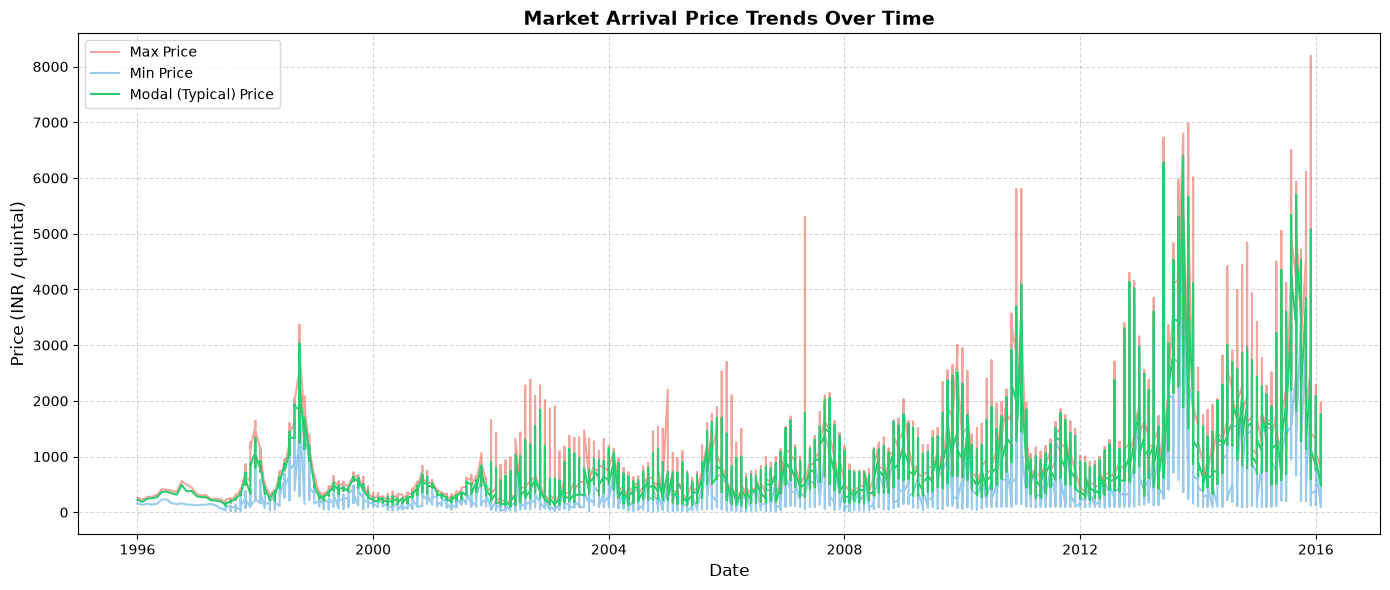

In [6]:
df_sorted = df_cleaned.sort_values('date').dropna(subset=['date'])

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df_sorted['date'], df_sorted['priceMax'], color='#e74c3c', alpha=0.5, label='Max Price')
ax.plot(df_sorted['date'], df_sorted['priceMin'], color='#3498db', alpha=0.5, label='Min Price')
ax.plot(df_sorted['date'], df_sorted['priceMod'], color='#2ecc71', linewidth=1.5, label='Modal (Typical) Price')

ax.set_title("Market Arrival Price Trends Over Time", fontsize=14, fontweight='bold')
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Price (INR / quintal)", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 6. Summary & Conclusion

- **Data Ingestion**: Successfully loaded and verified 10,227 market records.
- **Data Quality**: Evaluated null counts, deduplicated entries, standardized categorical text fields, and parsed datetime formats.
- **Outliers**: Identified and handled extreme price anomalies using the IQR method.
- **NumPy Analytics**: Calculated robust central tendencies, dispersion, percentiles, and vectorized condition masks.
- **Insights**: Demonstrated market price seasonality and volatility over time.
